# 02 — Dropout robustness (main result)

**Question.** How much does random sensor dropout (p = 0.3) cost each method, compared with noise only (p = 0), when
baselines are trained on the same corruption distribution?

Primary baselines: SHRED-dropout and SDN-dropout (zero-fill, trained with p = 0.3).

**Setup.** Nektar cylinder wake (Raissi PINN data), 200 snapshots × 5000 grid points (100 × 50, x∈[1,8], y∈[−2,2]).
Target: both velocity components, state = [u; v] (10 000 values). N = 8 probes, each reading u and v at one grid point,
placed by block-QR pivoting over grid points on the rank-16 POD basis of the training data. Lags = 10, interleaved
80/10/10 window split, seeds {0, 1, 2} (seed changes split, probe locations, POD basis and init). GRU for all recurrent models.

**Corruption (identical for all methods).** Gaussian noise σ = 0.05 × per-channel training std, added in unscaled
units (fresh per batch in training; fixed seeded realisation at test). Dropout: each probe fails with probability p for
the whole lag window (both channels), at least one probe survives. Training p = 0.3 for "-dropout" and masked models.
Test: p = 0 and p = 0.3, 10 fixed draws per test window, shared across methods (and gappy POD).
Zero-fill methods see 0 in the min-max scaled input space (= training minimum of that probe, not "no signal").
Masked methods (SenseiverSDN, RobustSHREDv1/v2) exclude failed probes from attention (key padding mask + learned null
token); gappy POD solves least squares with the available rows, rank r' = min(16, 2·available), clipped to the
training range. Early stopping uses a validation set corrupted like the method's training data.

**Caveats.** Relative L2 error over the stacked [u; v] field (dominated by u, whose mean flow is ≈ 1); u and v errors are
also reported separately. ~19 test windows per seed × 10 corruption draws (draws are not independent windows).

In [1]:
RUN_TRAINING = False   # True: train runs that are not cached yet (cached runs are skipped)
QUICK = False          # True: 1 seed, 20 epochs, separate cache dir (smoke test)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import meeting_plots as mp
from get_shredded.meeting_runner import (
    LATENT_METHODS, load_arrays, load_config, load_results, load_seed_info, prepare_seed, run_all,
)

TIER_A = ["SHRED-noise", "SHRED-dropout", "SDN-noise", "SDN-dropout",
          "SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2", "GappyPOD"]
TIER_B = ["SHRED-dropout+mask"]
METHODS = TIER_A + TIER_B
OVERRIDES = ["meeting.methods=[" + ",".join(METHODS) + "]"]
if QUICK:
    OVERRIDES += ["meeting.seeds=[0]", "train.epochs=20", "outputs.root=outputs/meeting_2026-10-14_quick"]
cfg = load_config(OVERRIDES)
ROOT = cfg.outputs.root
if RUN_TRAINING:
    run_all(cfg)
results = load_results(ROOT)
print(f"{len(results)} completed runs in {ROOT}")

27 completed runs in outputs/meeting_2026-10-14


## Error at p = 0 and p = 0.3 (mean ± std over seeds) and parameter counts

In [2]:
display(Markdown(mp.summary_table(results, METHODS)))

| Method | Params | Seeds | Clean | p = 0 | p = 0.3 | p = 0.3 (u) | p = 0.3 (v) |
|---|---:|---:|---:|---:|---:|---:|---:|
| SHRED-noise | 4,213,854 | 3 | 0.0040 ± 0.0006 | 0.0047 ± 0.0006 | 0.1589 ± 0.0062 | 0.0832 ± 0.0041 | 0.4734 ± 0.0174 |
| SHRED-dropout | 4,213,854 | 3 | 0.0102 ± 0.0027 | 0.0108 ± 0.0025 | 0.0145 ± 0.0035 | 0.0076 ± 0.0018 | 0.0433 ± 0.0106 |
| SDN-noise | 4,156,350 | 3 | 0.0040 ± 0.0004 | 0.0071 ± 0.0006 | 0.1803 ± 0.0061 | 0.0928 ± 0.0040 | 0.5401 ± 0.0174 |
| SDN-dropout | 4,156,350 | 3 | 0.0101 ± 0.0012 | 0.0127 ± 0.0014 | 0.0243 ± 0.0017 | 0.0125 ± 0.0008 | 0.0728 ± 0.0054 |
| SenseiverSDN | 4,253,502 | 3 | 0.0152 ± 0.0017 | 0.0169 ± 0.0017 | 0.0283 ± 0.0046 | 0.0147 ± 0.0024 | 0.0846 ± 0.0138 |
| RobustSHREDv1 | 4,224,382 | 3 | 0.0108 ± 0.0015 | 0.0115 ± 0.0014 | 0.0150 ± 0.0011 | 0.0078 ± 0.0005 | 0.0449 ± 0.0034 |
| RobustSHREDv2 | 4,273,086 | 3 | 0.0094 ± 0.0009 | 0.0103 ± 0.0012 | 0.0151 ± 0.0019 | 0.0078 ± 0.0009 | 0.0451 ± 0.0056 |
| GappyPOD | – | 3 | 0.0007 ± 0.0000 | 0.0139 ± 0.0003 | 0.0916 ± 0.0089 | 0.0562 ± 0.0047 | 0.2551 ± 0.0269 |
| SHRED-dropout+mask | 4,215,390 | 3 | 0.0099 ± 0.0013 | 0.0102 ± 0.0013 | 0.0113 ± 0.0018 | 0.0059 ± 0.0009 | 0.0337 ± 0.0052 |

**Takeaway:** At p = 0 the noise-only models are best (SHRED-noise 0.0047, SDN-noise 0.0071); dropout-trained and masked models sit at 0.010–0.017. At p = 0.3 the noise-only models fail (0.159, 0.180) and gappy POD degrades to 0.092, while SHRED-dropout+mask 0.0113, SHRED-dropout 0.0145, RobustSHREDv1 0.0150, RobustSHREDv2 0.0151, SDN-dropout 0.0243, SenseiverSDN 0.0283. v errors are 4–6× the u errors. All networks have ≈ 4.2 M parameters (within 3%, decoder-dominated).

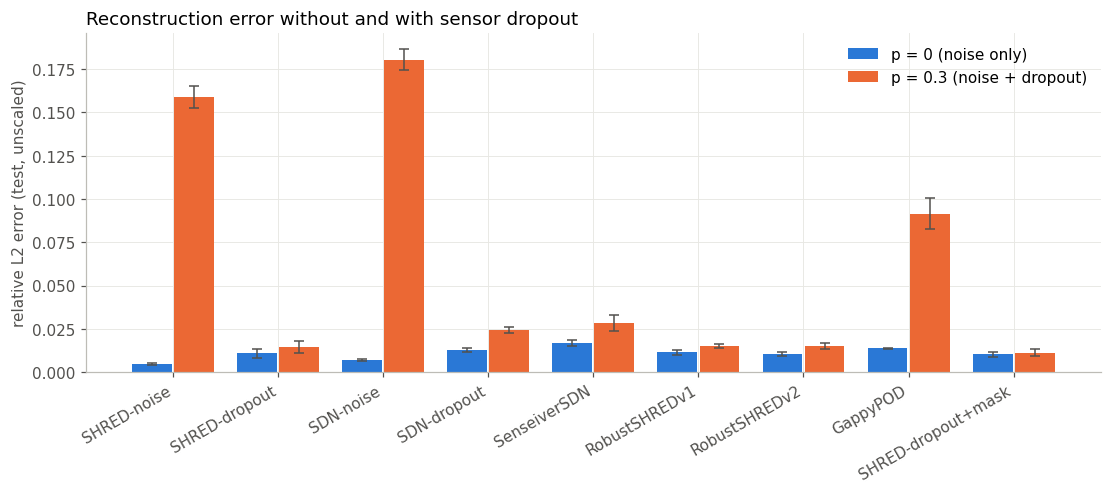

In [3]:
fig = mp.plot_error_bars(results, METHODS).figure
mp.save(fig, ROOT, "02_error_bars"); plt.show()

**Takeaway:** Training with dropout roughly doubles the p = 0 error of SHRED (0.0047 → 0.0108) but cuts its p = 0.3 error ≈ 11× (0.159 → 0.0145). Among dropout-trained models, SHRED-dropout, RobustSHREDv1 and RobustSHREDv2 are indistinguishable within seed std at p = 0.3, so attention-based masking gives no measurable gain over a zero-filled SHRED trained on the same corruption here. SHRED-dropout+mask (zero-fill + missing flags) is lowest (0.0113 ± 0.0018), but only ≈ 1 std below SHRED-dropout with 3 seeds.

## Error by number of failed probes k (p = 0.3 test set)

| k failed | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---:|---:|---:|---:|---:|---:|---:|
| samples (all seeds) | 32 | 98 | 171 | 166 | 77 | 17 | 9 |

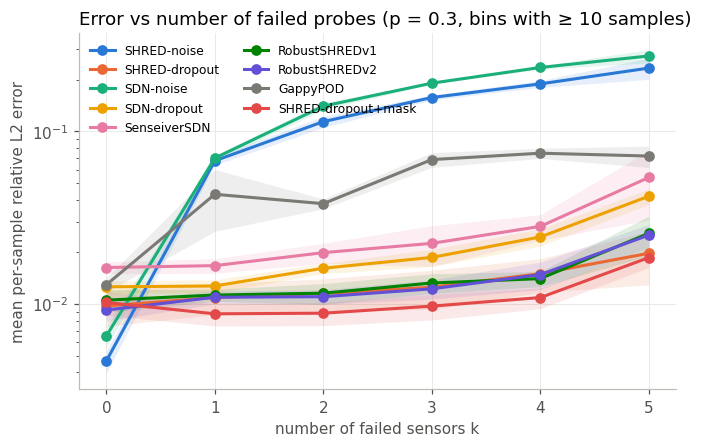

In [4]:
display(Markdown(mp.k_counts_table(ROOT, results, "SHRED-dropout")))
fig = mp.plot_by_k(ROOT, results, METHODS, "p0.3_err", "mean per-sample relative L2 error",
                   "Error vs number of failed probes (p = 0.3, bins with ≥ 10 samples)", logy=True).figure
mp.save(fig, ROOT, "02_error_by_k"); plt.show()

**Takeaway:** Only ≈ 6% of p = 0.3 test samples have k = 0, and the k = 5–6 bins are thin. Noise-only models jump ≈ 10× from k = 0 to k = 1; dropout-trained recurrent models rise smoothly from ≈ 0.01 to ≈ 0.02 at k = 5; gappy POD jumps to ≈ 0.04 at k = 1 and saturates at ≈ 0.07. SenseiverSDN and SDN-dropout are above the recurrent dropout-trained models at every k.

## Reconstruction panel at p = 0.3 (seed 0, test window 0, draw 0)

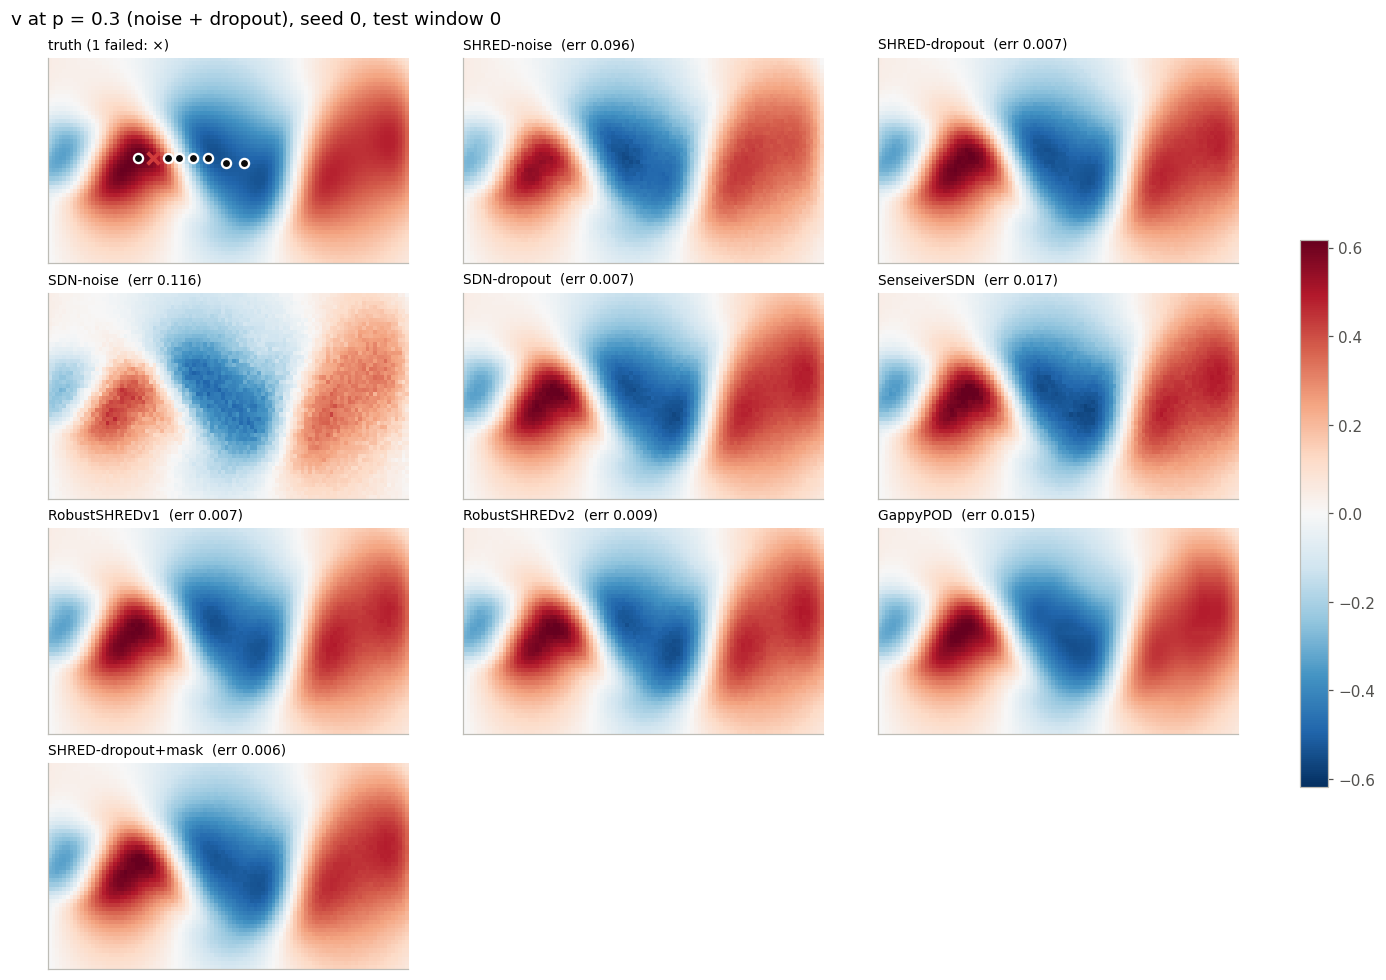

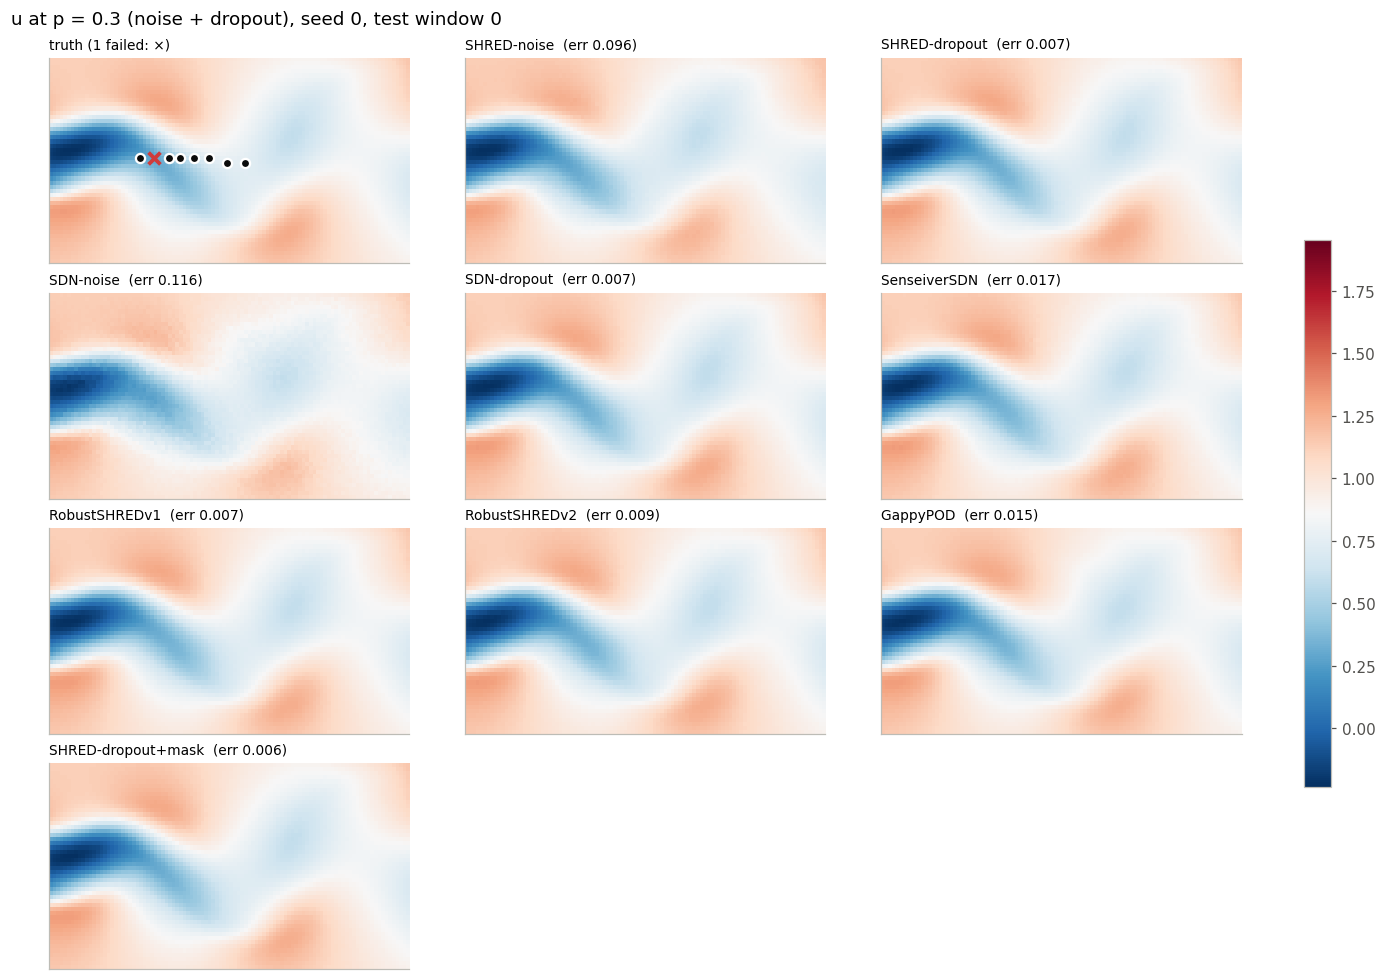

In [5]:
for channel in (1, 0):
    fig = mp.plot_reconstruction_panel(ROOT, results, METHODS, seed=0, window=0, cond="p0.3", channel=channel)
    mp.save(fig, ROOT, f"02_panel_{'uv'[channel]}"); plt.show()

**Takeaway:** In this example (1 failed probe) every dropout-trained or masked model is visually indistinguishable from the truth (v error 0.006–0.017); SHRED-noise loses amplitude and SDN-noise shows grainy noise and amplitude loss (errors 0.096 and 0.116).